# CLIMATEPRED AI
## An Explainable Machine Learning Framework for Urban Heat Prediction, Climate Trend Analysis and Climate Risk Intelligence

**Course:** 21CEO310T – Global Warming and Climate Change (LLT / CLA-2 working model)
**Team:** Balasudhan R (RA2411003012164), Deepshika (RA2411003012122)
**Institution:** SRM Institute of Science and Technology, Kattankulathur

---
### Problem
Cities are getting hotter because of urbanisation, loss of vegetation and a warming climate. Ordinary weather apps tell
you *what* the temperature will be, but not *why*, *where the risk is highest*, or *how the pattern is changing over time*.

### What this notebook does
1. Loads **real** NASA POWER (MERRA-2 / CERES) daily climate data for six Tamil Nadu cities (2015 – 2025).
2. Cleans the data and performs exploratory data analysis (EDA), including a **decade-scale warming-trend analysis**.
3. Engineers leakage-free, time-aware features.
4. Trains and compares **Linear Regression, Ridge, SVR, Decision Tree, Random Forest and XGBoost** to predict
   the *next day's maximum temperature*, using a **chronological** train/validation/test split.
5. Evaluates with **MAE, MSE, RMSE and R²**, plus time-series cross-validation and a **leave-one-city-out** generalisation test.
6. Classifies **heat-risk categories** (Normal / Elevated / Extreme) with Accuracy, Precision, Recall, F1, ROC-AUC and confusion matrices.
7. Explains the models with **SHAP** (global + individual predictions).
8. Runs an **AI Climate Intervention Simulator** — "what-if" scenarios for cloud cover, solar radiation, humidity and wind.

### Novelty
The novelty is in the *integration*: a single, reproducible framework that links regional climate data → leakage-free
temperature prediction → documented heat-risk classification → SHAP explanations → hypothetical mitigation scenarios,
with an honest unseen-city generalisation test. The individual algorithms are standard; the pipeline and evaluation design are ours.

## 1. Setup

In [1]:
import os, io, sys, warnings, json, time
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

SEED = 42
np.random.seed(SEED)

# Install anything missing (Colab already has sklearn / xgboost; shap sometimes missing)
try:
    import shap
except ImportError:
    os.system(f"{sys.executable} -m pip install -q shap")
    import shap
import xgboost as xgb
from sklearn.linear_model import LinearRegression, Ridge, LogisticRegression
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score, accuracy_score,
                             precision_recall_fscore_support, confusion_matrix, roc_auc_score,
                             classification_report, ConfusionMatrixDisplay)
import joblib

for d in ["data/raw", "data/processed", "models", "reports/figures"]:
    os.makedirs(d, exist_ok=True)

print("pandas", pd.__version__, "| sklearn", __import__("sklearn").__version__,
      "| xgboost", xgb.__version__, "| shap", shap.__version__)

pandas 3.0.5 | sklearn 1.9.1 | xgboost 3.4.1 | shap 0.54.1


## 2. Data acquisition — NASA POWER (real, public data)

**Source:** NASA POWER Daily API (https://power.larc.nasa.gov/) – MERRA-2 reanalysis + CERES satellite radiation.
**Period:** 2015-01-01 → 2025-10-31 (3 957 days per city). **Resolution:** 0.5° × 0.625° grid cell containing each city.

| Parameter | Meaning | Unit |
|---|---|---|
| T2M / T2M_MAX / T2M_MIN | Mean / max / min air temperature at 2 m | °C |
| RH2M | Relative humidity at 2 m | % |
| PRECTOTCORR | Precipitation (bias-corrected) | mm/day |
| WS2M | Wind speed at 2 m | m/s |
| ALLSKY_SFC_SW_DWN | Solar radiation reaching the surface | MJ/m²/day |
| CLOUD_AMT | Cloud amount | % |
| PS | Surface pressure | kPa |

The cell below downloads the CSVs directly from NASA when run in Colab. If the files are already present in `data/raw/`
(e.g. from the submitted ZIP) it just uses them, so results are reproducible offline too.

In [2]:
CITIES = {
    "Chennai":         (13.08, 80.27),
    "Coimbatore":      (11.02, 76.96),
    "Madurai":         ( 9.93, 78.12),
    "Tiruchirappalli": (10.79, 78.70),
    "Salem":           (11.66, 78.15),
    "Tirunelveli":     ( 8.71, 77.76),
}
PARAMS = "T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,CLOUD_AMT,PS"
START, END = "20150101", "20251031"

def nasa_power_url(lat, lon):
    return ("https://power.larc.nasa.gov/api/temporal/daily/point?"
            f"parameters={PARAMS}&community=AG&longitude={lon}&latitude={lat}"
            f"&start={START}&end={END}&format=CSV")

def download_city(city, lat, lon):
    path = f"data/raw/{city.lower()}.csv"
    if os.path.exists(path):
        return path, "cached"
    import urllib.request
    for attempt in range(3):
        try:
            urllib.request.urlretrieve(nasa_power_url(lat, lon), path)
            return path, "downloaded"
        except Exception as e:
            time.sleep(3)
            err = e
    raise RuntimeError(f"Could not download {city}: {err}")

for city, (lat, lon) in CITIES.items():
    path, how = download_city(city, lat, lon)
    print(f"{city:16s} {how:10s} {path}")

Chennai          cached     data/raw/chennai.csv
Coimbatore       cached     data/raw/coimbatore.csv
Madurai          cached     data/raw/madurai.csv
Tiruchirappalli  cached     data/raw/tiruchirappalli.csv
Salem            cached     data/raw/salem.csv
Tirunelveli      cached     data/raw/tirunelveli.csv


## 3. Loading and cleaning

NASA POWER CSVs begin with a metadata header block (`-BEGIN HEADER- … -END HEADER-`) and encode missing values as **-999**.
Dates are given as `YEAR` + `DOY` (day of year), which we convert to a proper date.

In [3]:
def load_city_csv(path, city):
    with open(path) as f:
        lines = f.readlines()
    start = next(i for i, l in enumerate(lines) if l.startswith("-END HEADER-")) + 1
    df = pd.read_csv(io.StringIO("".join(lines[start:])))
    df["date"] = pd.to_datetime(df["YEAR"].astype(str) + "-" + df["DOY"].astype(str), format="%Y-%j")
    df["city"] = city
    df["lat"], df["lon"] = CITIES[city]
    return df.drop(columns=["YEAR", "DOY"])

raw = pd.concat([load_city_csv(f"data/raw/{c.lower()}.csv", c) for c in CITIES], ignore_index=True)
raw = raw.replace(-999, np.nan)
print("Shape:", raw.shape)
raw.head()

Shape: (23742, 13)


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,CLOUD_AMT,PS,date,city,lat,lon
0,24.57,28.22,21.27,84.66,0.23,1.59,14.01,40.37,100.37,2015-01-01,Chennai,13.08,80.27
1,25.12,28.12,22.65,86.96,0.22,2.35,17.32,18.67,100.63,2015-01-02,Chennai,13.08,80.27
2,25.11,28.14,22.76,86.51,0.04,2.15,17.68,21.11,100.77,2015-01-03,Chennai,13.08,80.27
3,24.95,28.32,22.55,83.45,0.00,1.99,19.38,11.31,100.78,2015-01-04,Chennai,13.08,80.27
4,24.49,28.05,21.68,84.16,0.01,2.33,18.50,17.95,100.75,2015-01-05,Chennai,13.08,80.27


In [4]:
# --- Missing values, duplicates, basic sanity ---
print("Date range:", raw.date.min().date(), "→", raw.date.max().date())
print("Rows per city:\n", raw.city.value_counts().to_string())
print("\nMissing values per column:\n", raw.isna().sum().to_string())
print("\nDuplicate (city, date) rows:", raw.duplicated(["city", "date"]).sum())

Date range: 2015-01-01 → 2025-10-31
Rows per city:
 city
Chennai            3957
Coimbatore         3957
Madurai            3957
Tiruchirappalli    3957
Salem              3957
Tirunelveli        3957

Missing values per column:
 T2M                  0
T2M_MAX              0
T2M_MIN              0
RH2M                 0
PRECTOTCORR          0
WS2M                 0
ALLSKY_SFC_SW_DWN    0
CLOUD_AMT            0
PS                   0
date                 0
city                 0
lat                  0
lon                  0

Duplicate (city, date) rows: 0


In [5]:
# --- Treatment ---
df = raw.sort_values(["city", "date"]).drop_duplicates(["city", "date"]).copy()
weather_cols = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "WS2M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT", "PS"]
# time-interpolate any gaps within each city (none expected, but keeps the pipeline robust)
df[weather_cols] = df.groupby("city")[weather_cols].transform(lambda s: s.interpolate(limit_direction="both"))
# physical sanity check: max >= mean >= min
bad = (df.T2M_MAX < df.T2M) | (df.T2M < df.T2M_MIN)
print("Rows violating Tmax ≥ Tmean ≥ Tmin:", int(bad.sum()))
df = df[~bad].reset_index(drop=True)
df.describe().T.round(2)

Rows violating Tmax ≥ Tmean ≥ Tmin: 0


,count,mean,min,25%,50%,75%,max,std
T2M,23742.0,26.902189,18.82,24.84,26.77,28.86,35.88,2.66371
T2M_MAX,23742.0,32.452077,21.96,29.39,32.23,35.2,43.99,3.672329
T2M_MIN,23742.0,22.6126,12.46,21.08,22.96,24.41,30.65,2.699218
RH2M,23742.0,72.64411,30.04,64.0925,73.5,82.68,95.97,11.831659
PRECTOTCORR,23742.0,2.9986,0.0,0.01,0.5,3.18,209.16,6.753385
WS2M,23742.0,2.432305,0.32,1.71,2.28,3.01,11.28,0.996766
ALLSKY_SFC_SW_DWN,23742.0,18.950772,0.98,16.45,19.6,22.12,27.95,4.281489
CLOUD_AMT,23742.0,64.073167,0.13,39.7825,69.875,91.83,99.98,29.45171
PS,23742.0,98.021004,94.21,97.3,98.21,99.02,101.23,1.679666
date,23742,2020-06-01 00:00:00,2015-01-01 00:00:00,2017-09-16 00:00:00,2020-06-01 00:00:00,2023-02-15 00:00:00,2025-10-31 00:00:00,NaN


### Outlier analysis (IQR method)
We *detect* outliers but do **not** delete them: in climate data, extreme values (heat-wave days, cyclone rainfall) are exactly
the physically real events we care about. Deleting them would bias the heat-risk analysis.

,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,CLOUD_AMT,PS
city,,,,,,,,,
Chennai,0,0,33,0,471,49,97,0,0
Coimbatore,149,27,183,48,279,71,5,0,6
Madurai,5,0,180,1,469,105,108,0,0
Salem,10,0,109,3,462,94,70,0,0
Tiruchirappalli,0,0,97,0,518,127,94,0,0
Tirunelveli,172,28,254,15,453,3,62,0,15


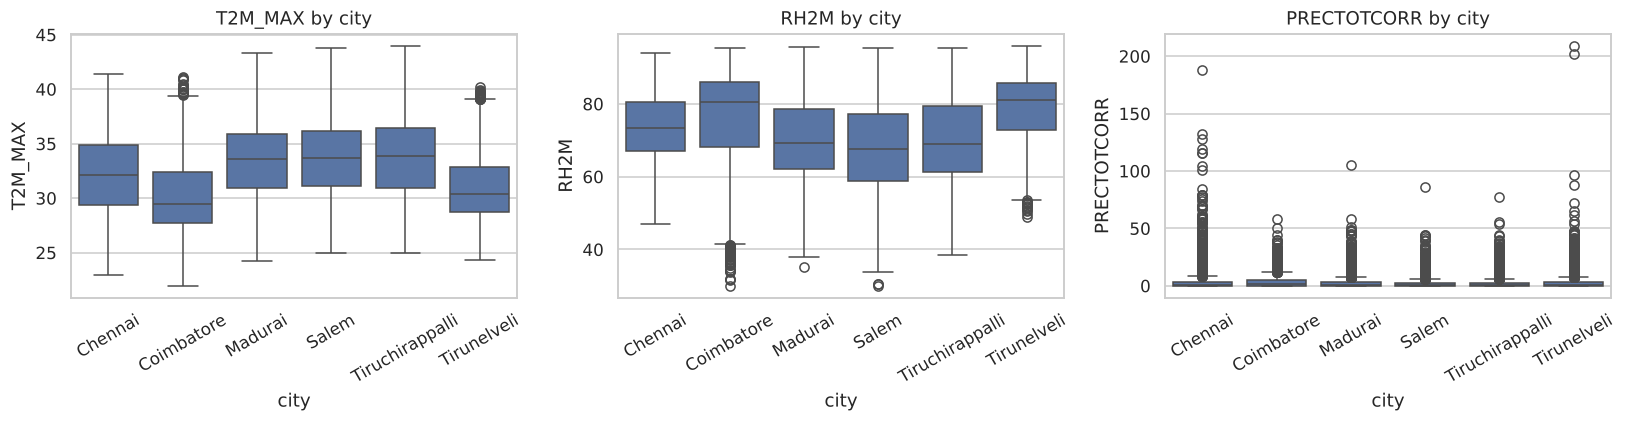

In [6]:
def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return ((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum()

out = df.groupby("city")[weather_cols].agg(iqr_outliers)
display(out)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["T2M_MAX", "RH2M", "PRECTOTCORR"]):
    sns.boxplot(data=df, x="city", y=col, ax=ax); ax.tick_params(axis="x", rotation=30); ax.set_title(f"{col} by city")
plt.tight_layout(); plt.savefig("reports/figures/01_boxplots.png"); plt.show()

## 4. Exploratory Data Analysis

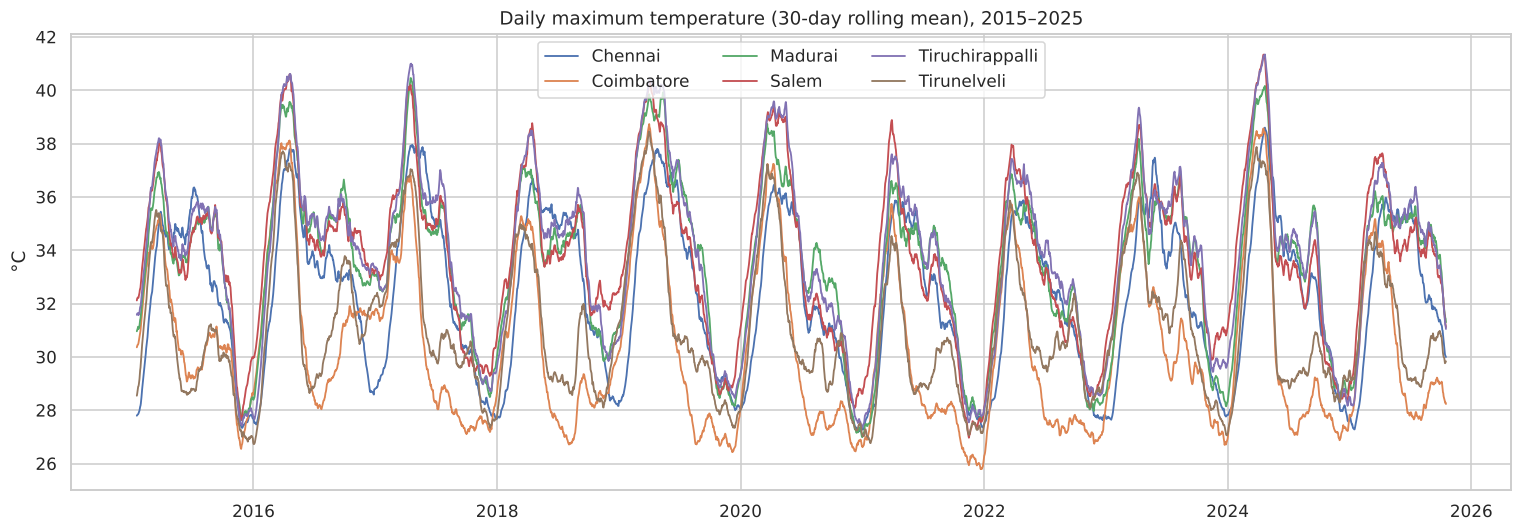

In [7]:
# Daily maximum temperature over time (30-day rolling mean for readability)
fig, ax = plt.subplots(figsize=(14, 5))
for city, g in df.groupby("city"):
    ax.plot(g.date, g.T2M_MAX.rolling(30, center=True).mean(), label=city, lw=1.2)
ax.set_title("Daily maximum temperature (30-day rolling mean), 2015–2025"); ax.set_ylabel("°C"); ax.legend(ncol=3)
plt.tight_layout(); plt.savefig("reports/figures/02_tmax_timeseries.png"); plt.show()

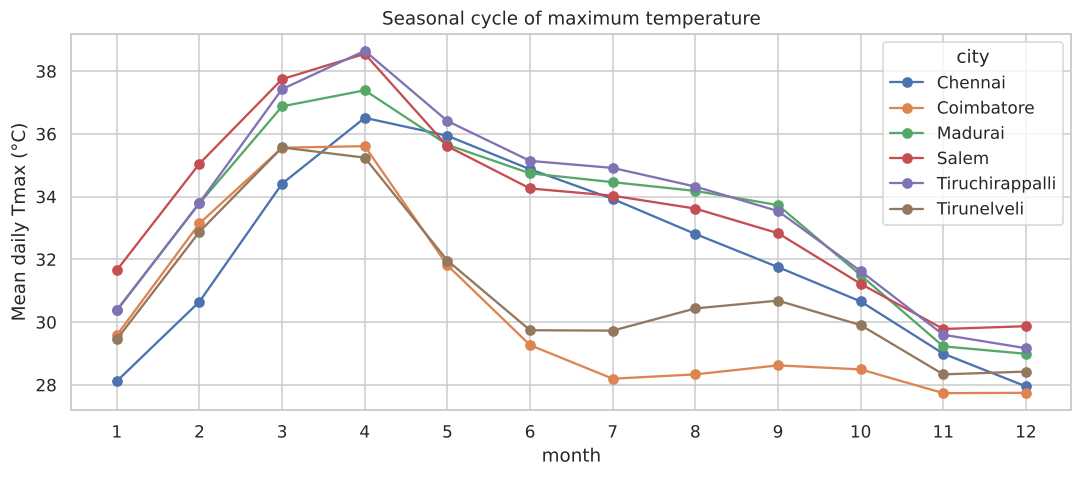

city,Chennai,Coimbatore,Madurai,Salem,Tiruchirappalli,Tirunelveli
month,,,,,,
1,28.1,29.6,30.4,31.7,30.4,29.5
2,30.7,33.1,33.8,35.1,33.8,32.9
3,34.4,35.6,36.9,37.7,37.4,35.6
4,36.5,35.6,37.4,38.6,38.6,35.2
5,35.9,31.8,35.7,35.6,36.4,32.0
6,34.9,29.3,34.7,34.3,35.1,29.7
7,33.9,28.2,34.5,34.0,34.9,29.7
8,32.8,28.3,34.2,33.6,34.3,30.4
9,31.8,28.6,33.7,32.8,33.5,30.7


In [8]:
# Seasonal cycle: mean monthly Tmax per city
df["month"] = df.date.dt.month
clim = df.pivot_table(index="month", columns="city", values="T2M_MAX", aggfunc="mean")
ax = clim.plot(figsize=(10, 4.5), marker="o")
ax.set_xticks(range(1, 13)); ax.set_ylabel("Mean daily Tmax (°C)"); ax.set_title("Seasonal cycle of maximum temperature")
plt.tight_layout(); plt.savefig("reports/figures/03_seasonal_cycle.png"); plt.show()
clim.round(1)

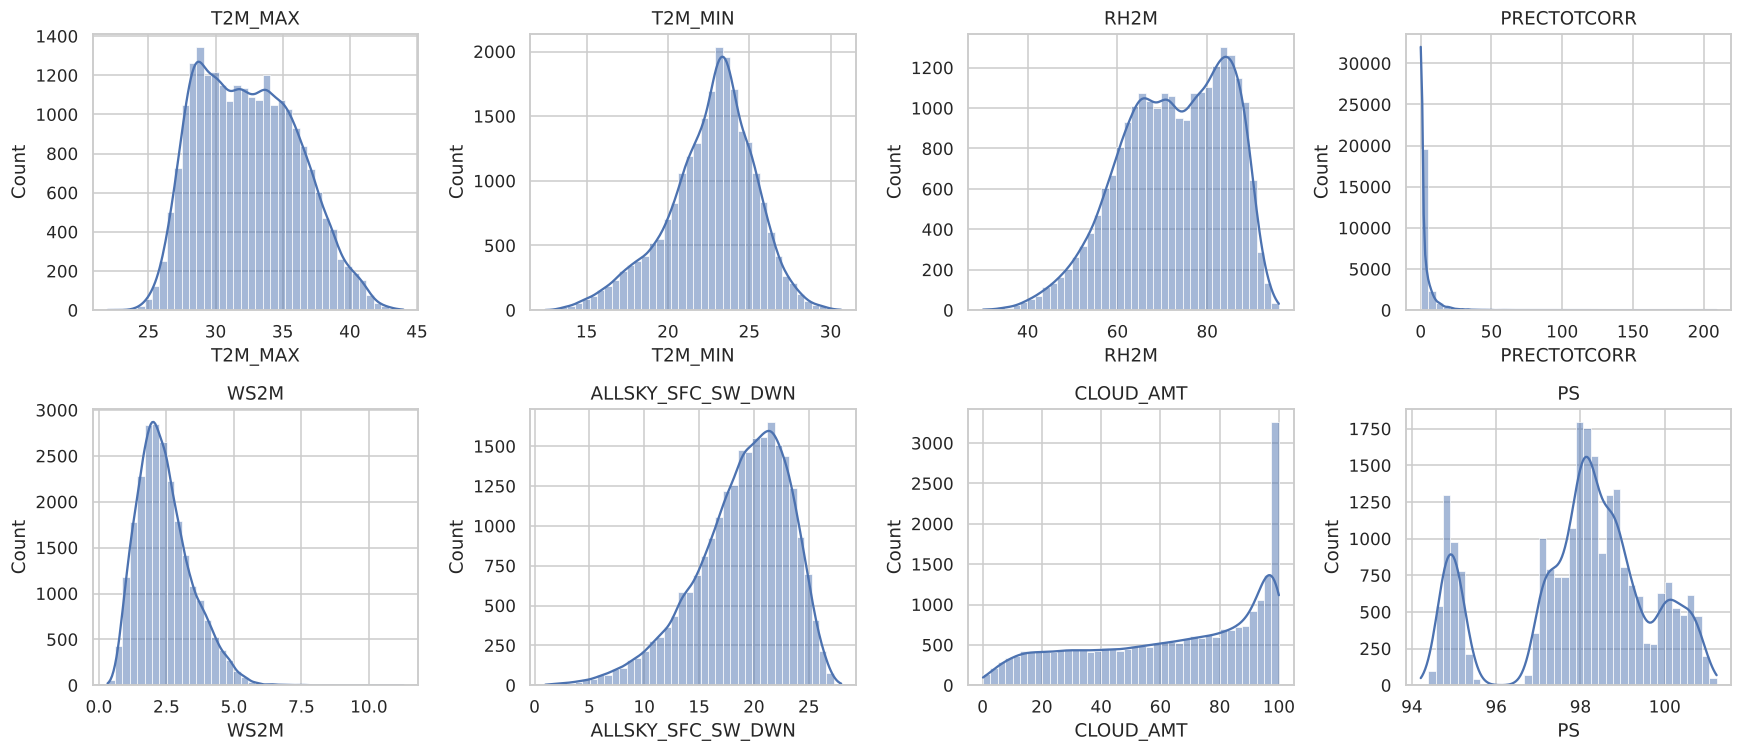

In [9]:
# Distributions
fig, axes = plt.subplots(2, 4, figsize=(16, 7)); axes = axes.ravel()
for ax, col in zip(axes, ["T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "WS2M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT", "PS"]):
    sns.histplot(df[col], bins=40, ax=ax, kde=True); ax.set_title(col)
plt.tight_layout(); plt.savefig("reports/figures/04_distributions.png"); plt.show()

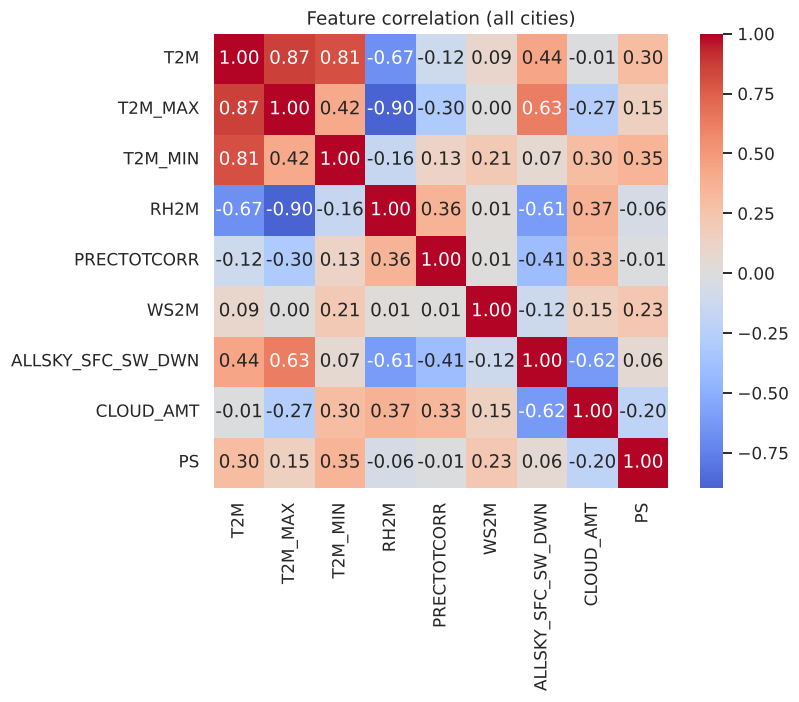

Correlation with T2M_MAX:
 T2M                  0.866
ALLSKY_SFC_SW_DWN    0.628
T2M_MIN              0.416
PS                   0.150
WS2M                 0.001
CLOUD_AMT           -0.268
PRECTOTCORR         -0.300
RH2M                -0.898


In [10]:
# Correlation heatmap
corr = df[weather_cols].corr()
plt.figure(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True)
plt.title("Feature correlation (all cities)"); plt.tight_layout(); plt.savefig("reports/figures/05_correlation.png"); plt.show()
print("Correlation with T2M_MAX:\n", corr["T2M_MAX"].drop("T2M_MAX").sort_values(ascending=False).round(3).to_string())

### Climate-trend analysis: is Tamil Nadu warming?
For the Global Warming & Climate Change context we fit a linear trend to the **annual mean temperature** of each city
(2015–2024, complete years only) and express it in °C per decade. We also count the number of "hot days" (Tmax ≥ 38 °C) per year.
*Caveat:* ten years is a short window — this shows the recent tendency, not a long-term climate normal.

,trend_Tmean_°C/decade,trend_Tmax_°C/decade,trend_hot_days/decade,mean_hot_days_per_year
city,,,,
Chennai,-0.04,-0.62,7.88,14.0
Coimbatore,-0.33,-1.10,4.30,12.5
Madurai,-0.41,-1.02,-4.55,38.9
Salem,-0.42,-1.07,4.79,48.3
Tiruchirappalli,-0.31,-0.86,-7.76,52.6
Tirunelveli,0.14,-0.09,-0.24,10.4


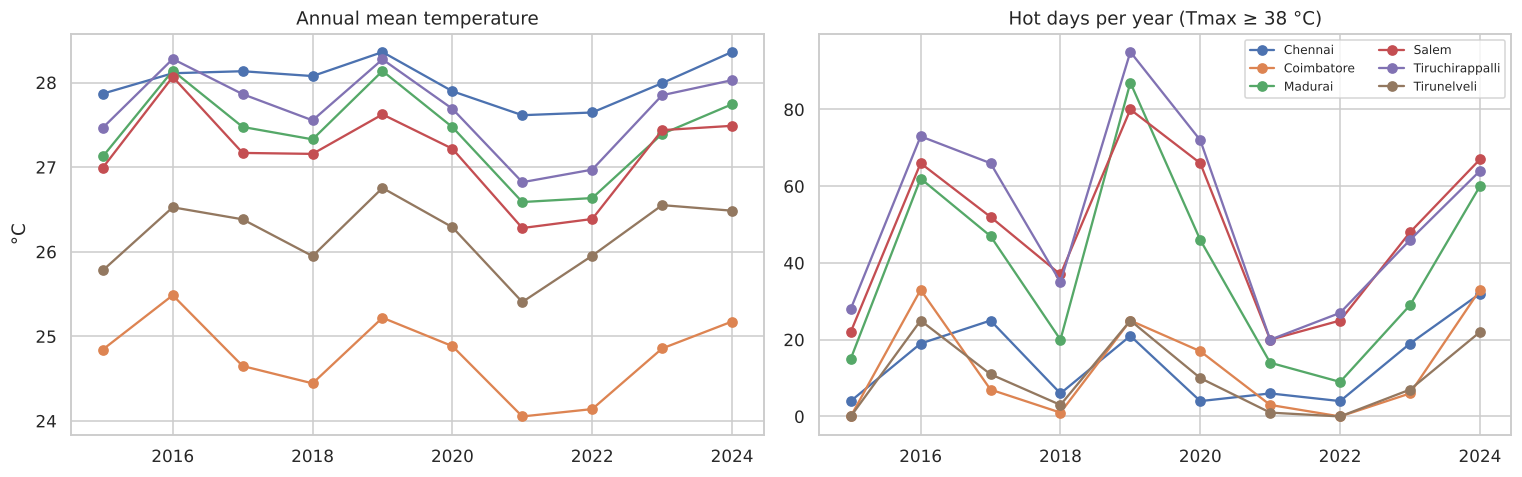

In [11]:
annual = df[df.date.dt.year <= 2024].groupby(["city", df.date.dt.year.rename("year")]).agg(
    T2M=("T2M", "mean"), T2M_MAX=("T2M_MAX", "mean"), hot_days=("T2M_MAX", lambda s: (s >= 38).sum())).reset_index()
trend_rows = []
for city, g in annual.groupby("city"):
    slope_mean = np.polyfit(g.year, g.T2M, 1)[0] * 10
    slope_max = np.polyfit(g.year, g.T2M_MAX, 1)[0] * 10
    slope_hot = np.polyfit(g.year, g.hot_days, 1)[0] * 10
    trend_rows.append({"city": city, "trend_Tmean_°C/decade": slope_mean, "trend_Tmax_°C/decade": slope_max,
                       "trend_hot_days/decade": slope_hot, "mean_hot_days_per_year": g.hot_days.mean()})
trend = pd.DataFrame(trend_rows).set_index("city").round(2)
display(trend)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for city, g in annual.groupby("city"):
    axes[0].plot(g.year, g.T2M, marker="o", label=city)
    axes[1].plot(g.year, g.hot_days, marker="o", label=city)
axes[0].set_title("Annual mean temperature"); axes[0].set_ylabel("°C")
axes[1].set_title("Hot days per year (Tmax ≥ 38 °C)"); axes[1].legend(ncol=2, fontsize=8)
plt.tight_layout(); plt.savefig("reports/figures/06_warming_trend.png"); plt.show()

## 5. Feature engineering (leakage-free)

**Prediction task:** given everything observed up to and including day *t*, predict the **maximum temperature on day t+1**.

We therefore only use information available on day *t*:
- today's weather (T2M, T2M_MAX, T2M_MIN, RH2M, rainfall, wind, solar, cloud, pressure)
- lags of Tmax (1, 2, 3, 7 days) and rolling means (7, 30 days) and rolling std (7 days)
- calendar features: month, cyclic day-of-year (sin/cos)
- location: latitude, longitude

Tomorrow's actual humidity/rain/etc. are **never** used as inputs, because they would not be known at prediction time.

In [12]:
def make_features(d):
    d = d.sort_values(["city", "date"]).copy()
    g = d.groupby("city")
    d["target_tmax_next"] = g["T2M_MAX"].shift(-1)                    # <- target: tomorrow's Tmax
    for lag in [1, 2, 3, 7]:
        d[f"tmax_lag{lag}"] = g["T2M_MAX"].shift(lag)
    d["tmax_roll7"] = g["T2M_MAX"].transform(lambda s: s.rolling(7).mean())
    d["tmax_roll30"] = g["T2M_MAX"].transform(lambda s: s.rolling(30).mean())
    d["tmax_std7"] = g["T2M_MAX"].transform(lambda s: s.rolling(7).std())
    d["tmin_lag1"] = g["T2M_MIN"].shift(1)
    d["rain_roll3"] = g["PRECTOTCORR"].transform(lambda s: s.rolling(3).sum())
    d["diurnal_range"] = d["T2M_MAX"] - d["T2M_MIN"]
    doy = d.date.dt.dayofyear
    d["doy_sin"], d["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
    d["month"] = d.date.dt.month
    return d.dropna().reset_index(drop=True)

data = make_features(df)
FEATURES = ["T2M", "T2M_MAX", "T2M_MIN", "RH2M", "PRECTOTCORR", "WS2M", "ALLSKY_SFC_SW_DWN", "CLOUD_AMT", "PS",
            "tmax_lag1", "tmax_lag2", "tmax_lag3", "tmax_lag7", "tmax_roll7", "tmax_roll30", "tmax_std7",
            "tmin_lag1", "rain_roll3", "diurnal_range", "doy_sin", "doy_cos", "month", "lat", "lon"]
TARGET = "target_tmax_next"
print("Modelling rows:", len(data), "| features:", len(FEATURES))
data.to_csv("data/processed/climatepred_features.csv", index=False)
data[FEATURES + [TARGET]].head()

Modelling rows: 23562 | features: 24


,T2M,T2M_MAX,T2M_MIN,RH2M,PRECTOTCORR,WS2M,ALLSKY_SFC_SW_DWN,CLOUD_AMT,PS,tmax_lag1,...,tmax_std7,tmin_lag1,rain_roll3,diurnal_range,doy_sin,doy_cos,month,lat,lon,target_tmax_next
0,24.34,28.76,21.20,74.08,0.00,2.95,18.60,40.91,100.96,29.08,...,0.401361,21.12,0.01,7.56,0.493468,0.869764,1,13.08,80.27,28.89
1,24.04,28.89,20.17,76.75,0.00,3.25,19.28,22.13,100.98,28.76,...,0.348186,21.20,0.00,8.72,0.508356,0.861147,1,13.08,80.27,28.48
2,24.00,28.48,20.54,78.93,0.01,3.14,17.38,30.84,100.97,28.89,...,0.291703,20.17,0.01,7.94,0.523094,0.852275,2,13.08,80.27,28.52
3,24.01,28.52,20.90,76.94,0.00,3.58,18.72,32.55,101.06,28.48,...,0.237537,20.54,0.01,7.62,0.537677,0.843151,2,13.08,80.27,28.70
4,24.30,28.70,21.42,72.62,0.01,3.77,19.11,39.57,101.23,28.52,...,0.235362,20.90,0.02,7.28,0.552101,0.833777,2,13.08,80.27,28.80


## 6. Chronological train / validation / test split (70 / 15 / 15)
Random shuffling would let the model "see the future" (a day in 2024 while training on 2025). We split strictly by date,
so the test set is entirely **after** the training period — the same situation a deployed model faces.

In [13]:
dates_sorted = np.sort(data.date.unique())
cut_train = dates_sorted[int(len(dates_sorted) * 0.70)]
cut_val = dates_sorted[int(len(dates_sorted) * 0.85)]
train = data[data.date < cut_train]; val = data[(data.date >= cut_train) & (data.date < cut_val)]; test = data[data.date >= cut_val]
print(f"Train: {train.date.min().date()} → {train.date.max().date()}  ({len(train)} rows)")
print(f"Val  : {val.date.min().date()} → {val.date.max().date()}  ({len(val)} rows)")
print(f"Test : {test.date.min().date()} → {test.date.max().date()}  ({len(test)} rows)")
X_train, y_train = train[FEATURES], train[TARGET]
X_val, y_val = val[FEATURES], val[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

Train: 2015-01-30 → 2022-08-08  (16488 rows)
Val  : 2022-08-09 → 2024-03-19  (3534 rows)
Test : 2024-03-20 → 2025-10-30  (3540 rows)


## 7. Model training and comparison
Baselines first, then increasingly flexible models. `Persistence` (tomorrow = today) is the naïve forecast every model must beat.

In [14]:
def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_true, y_pred)}

models = {
    "Persistence (baseline)": None,
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge Regression": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=10, epsilon=0.1, gamma="scale")),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, min_samples_leaf=20, random_state=SEED),
    "Random Forest": RandomForestRegressor(n_estimators=300, max_depth=14, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
    "XGBoost": xgb.XGBRegressor(n_estimators=600, learning_rate=0.03, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                                reg_lambda=1.0, random_state=SEED, n_jobs=-1),
}
results, fitted, preds_val, preds_test = [], {}, {}, {}
for name, model in models.items():
    t0 = time.time()
    if model is None:
        pv, pt = X_val["T2M_MAX"].values, X_test["T2M_MAX"].values
    else:
        model.fit(X_train, y_train); fitted[name] = model
        pv, pt = model.predict(X_val), model.predict(X_test)
    preds_val[name], preds_test[name] = pv, pt
    mv, mt = regression_metrics(y_val, pv), regression_metrics(y_test, pt)
    results.append({"Model": name, **{f"Val {k}": v for k, v in mv.items()}, **{f"Test {k}": v for k, v in mt.items()},
                    "Train time (s)": time.time() - t0})
    print(f"{name:24s} val MAE={mv['MAE']:.3f} R²={mv['R2']:.3f} | test MAE={mt['MAE']:.3f} RMSE={mt['RMSE']:.3f} R²={mt['R2']:.3f}")
results_df = pd.DataFrame(results).set_index("Model").round(4)
results_df.to_csv("reports/model_comparison.csv")
results_df

Persistence (baseline)   val MAE=1.012 R²=0.838 | test MAE=1.137 RMSE=1.546 R²=0.827
Linear Regression        val MAE=0.953 R²=0.866 | test MAE=1.064 RMSE=1.385 R²=0.861
Ridge Regression         val MAE=0.953 R²=0.866 | test MAE=1.064 RMSE=1.385 R²=0.861


SVR (RBF)                val MAE=0.923 R²=0.868 | test MAE=1.009 RMSE=1.326 R²=0.873
Decision Tree            val MAE=0.988 R²=0.856 | test MAE=1.078 RMSE=1.415 R²=0.855


Random Forest            val MAE=0.921 R²=0.873 | test MAE=1.014 RMSE=1.332 R²=0.872


XGBoost                  val MAE=0.922 R²=0.871 | test MAE=1.016 RMSE=1.326 R²=0.873


,Val MAE,Val MSE,Val RMSE,Val R2,Test MAE,Test MSE,Test RMSE,Test R2,Train time (s)
Model,,,,,,,,,
Persistence (baseline),1.0122,1.9831,1.4082,0.8377,1.1367,2.3886,1.5455,0.8271,0.0227
Linear Regression,0.9527,1.6371,1.2795,0.8660,1.0636,1.9187,1.3852,0.8611,0.0222
Ridge Regression,0.9527,1.6372,1.2795,0.8660,1.0636,1.9187,1.3852,0.8611,0.0135
SVR (RBF),0.9235,1.6128,1.2700,0.8680,1.0092,1.7572,1.3256,0.8728,22.3206
Decision Tree,0.9883,1.7586,1.3261,0.8561,1.0776,2.0025,1.4151,0.8551,0.1989
Random Forest,0.9209,1.5567,1.2477,0.8726,1.0140,1.7733,1.3317,0.8717,27.6064
XGBoost,0.9223,1.5706,1.2532,0.8714,1.0159,1.7577,1.3258,0.8728,1.1224


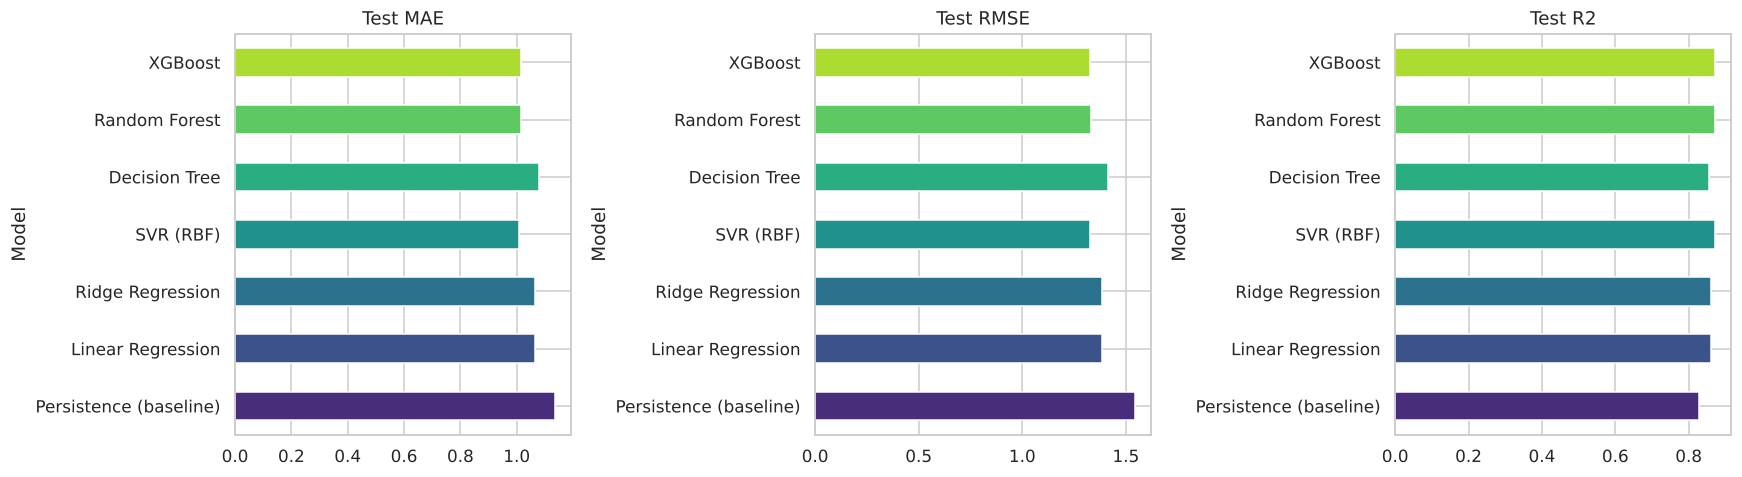

Best model selected on validation set: Random Forest


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, m in zip(axes, ["Test MAE", "Test RMSE", "Test R2"]):
    results_df[m].plot.barh(ax=ax, color=sns.color_palette("viridis", len(results_df))); ax.set_title(m); ax.set_xlabel("")
plt.tight_layout(); plt.savefig("reports/figures/07_model_comparison.png"); plt.show()

best_name = results_df.drop(index="Persistence (baseline)")["Val MAE"].idxmin()   # selected on VALIDATION, not test
best_model = fitted[best_name]
print("Best model selected on validation set:", best_name)

### Overfitting check
Comparing training error with validation/test error for each model tells us whether it memorised the training period.

In [16]:
over = []
for name, model in fitted.items():
    over.append({"Model": name, "Train MAE": mean_absolute_error(y_train, model.predict(X_train)),
                 "Val MAE": mean_absolute_error(y_val, preds_val[name]), "Test MAE": mean_absolute_error(y_test, preds_test[name])})
over_df = pd.DataFrame(over).set_index("Model").round(3)
over_df["Gap (Test−Train)"] = (over_df["Test MAE"] - over_df["Train MAE"]).round(3)
over_df

,Train MAE,Val MAE,Test MAE,Gap (Test−Train)
Model,,,,
Linear Regression,1.006,0.953,1.064,0.058
Ridge Regression,1.006,0.953,1.064,0.058
SVR (RBF),0.795,0.923,1.009,0.214
Decision Tree,0.927,0.988,1.078,0.151
Random Forest,0.546,0.921,1.014,0.468
XGBoost,0.764,0.922,1.016,0.252


### Hyperparameter tuning (validation set)
A small grid over the two most important XGBoost parameters, scored on the validation period — the test set stays untouched.

In [17]:
grid = [(d, lr) for d in [3, 5, 7] for lr in [0.02, 0.05, 0.1]]
tune = []
for d, lr in grid:
    m = xgb.XGBRegressor(n_estimators=600, learning_rate=lr, max_depth=d, subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, n_jobs=-1).fit(X_train, y_train)
    tune.append({"max_depth": d, "learning_rate": lr, "Val MAE": mean_absolute_error(y_val, m.predict(X_val))})
tune_df = pd.DataFrame(tune).sort_values("Val MAE").round(4)
display(tune_df.head())
bd, blr = int(tune_df.iloc[0].max_depth), float(tune_df.iloc[0].learning_rate)

# Final model: retrain on train+val with the tuned parameters, evaluate once on the held-out test period
X_trval, y_trval = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
final_model = xgb.XGBRegressor(n_estimators=600, learning_rate=blr, max_depth=bd, subsample=0.8, colsample_bytree=0.8,
                               random_state=SEED, n_jobs=-1).fit(X_trval, y_trval)
final_pred = final_model.predict(X_test)
final_metrics = regression_metrics(y_test, final_pred)
print(f"Tuned XGBoost (depth={bd}, lr={blr}) on TEST:", {k: round(v, 4) for k, v in final_metrics.items()})
joblib.dump(final_model, "models/xgb_tmax_next_day.joblib")
joblib.dump(fitted["Random Forest"], "models/rf_tmax_next_day.joblib")
json.dump({"features": FEATURES, "target": TARGET, "final_test_metrics": final_metrics, "best_val_model": best_name},
          open("models/metadata.json", "w"), indent=2, default=float)

,max_depth,learning_rate,Val MAE
3,5,0.02,0.9150
6,7,0.02,0.9188
0,3,0.02,0.9208
1,3,0.05,0.9251
4,5,0.05,0.9314


Tuned XGBoost (depth=5, lr=0.02) on TEST: {'MAE': 1.0018, 'MSE': 1.7201, 'RMSE': np.float64(1.3115), 'R2': 0.8755}


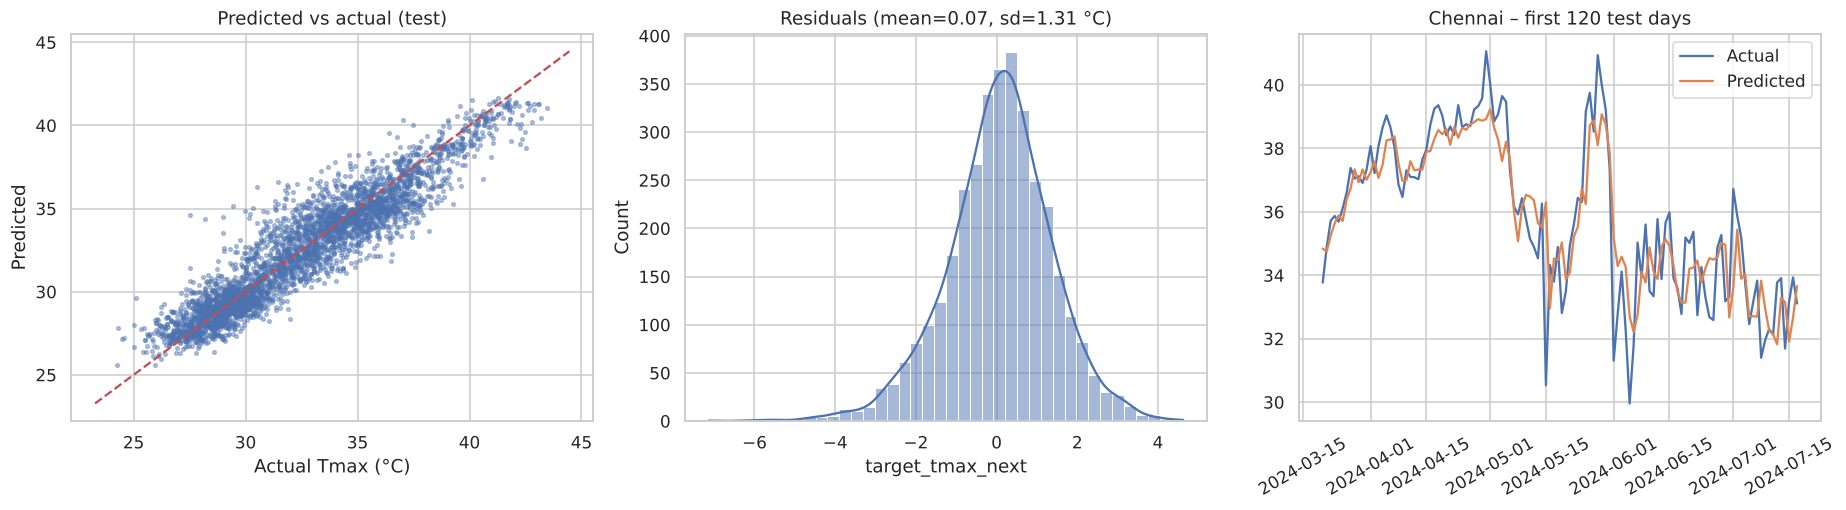

,MAE,MSE,RMSE,R2
city,,,,
Chennai,0.793,1.094,1.046,0.896
Coimbatore,0.868,1.292,1.137,0.901
Madurai,1.133,2.082,1.443,0.811
Salem,1.076,1.995,1.413,0.841
Tiruchirappalli,1.143,2.255,1.502,0.828
Tirunelveli,0.999,1.602,1.266,0.814


In [18]:
# Predicted vs actual, residuals, and a sample forecast strip for one city
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(y_test, final_pred, s=6, alpha=0.4); lims = [y_test.min() - 1, y_test.max() + 1]
axes[0].plot(lims, lims, "r--"); axes[0].set_xlabel("Actual Tmax (°C)"); axes[0].set_ylabel("Predicted"); axes[0].set_title("Predicted vs actual (test)")
res = y_test - final_pred
sns.histplot(res, bins=40, kde=True, ax=axes[1]); axes[1].set_title(f"Residuals (mean={res.mean():.2f}, sd={res.std():.2f} °C)")
sel = test.city == "Chennai"
axes[2].plot(test.date[sel].iloc[:120], y_test[sel].iloc[:120], label="Actual"); axes[2].plot(test.date[sel].iloc[:120], final_pred[sel.values][:120], label="Predicted")
axes[2].set_title("Chennai – first 120 test days"); axes[2].legend(); axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.savefig("reports/figures/08_pred_vs_actual.png"); plt.show()

# Per-city test error
percity = test.assign(pred=final_pred).groupby("city").apply(
    lambda g: pd.Series(regression_metrics(g[TARGET], g.pred))).round(3)
percity

## 8. Generalisation
### 8a. Time-series cross-validation
`TimeSeriesSplit` makes 5 expanding-window folds — each fold trains on the past and validates on the following block.

In [19]:
cv_rows = []
tscv = TimeSeriesSplit(n_splits=5)
Xcv, ycv = data.sort_values("date")[FEATURES], data.sort_values("date")[TARGET]
for name, maker in {"Linear Regression": lambda: make_pipeline(StandardScaler(), LinearRegression()),
                    "Random Forest": lambda: RandomForestRegressor(n_estimators=150, max_depth=14, min_samples_leaf=3, n_jobs=-1, random_state=SEED),
                    "XGBoost": lambda: xgb.XGBRegressor(n_estimators=400, learning_rate=blr, max_depth=bd, subsample=0.8, colsample_bytree=0.8, random_state=SEED, n_jobs=-1)}.items():
    maes = []
    for tr, te in tscv.split(Xcv):
        m = maker().fit(Xcv.iloc[tr], ycv.iloc[tr]); maes.append(mean_absolute_error(ycv.iloc[te], m.predict(Xcv.iloc[te])))
    cv_rows.append({"Model": name, "CV MAE mean": np.mean(maes), "CV MAE std": np.std(maes), "folds": np.round(maes, 3).tolist()})
pd.DataFrame(cv_rows).set_index("Model").round(3)

,CV MAE mean,CV MAE std,folds
Model,,,
Linear Regression,0.997,0.041,"[1.032, 0.969, 0.932, 1.038, 1.015]"
Random Forest,0.965,0.043,"[1.007, 0.944, 0.895, 1.013, 0.964]"
XGBoost,0.957,0.042,"[0.996, 0.936, 0.891, 1.007, 0.954]"


### 8b. Leave-one-city-out: does the model transfer to an unseen location?
Each city is held out in turn; the model is trained on the other five and tested on the held-out city's test period.
This is a much harder test than the chronological split and shows whether the model learned *climate physics* or *city identity*.

,MAE,MSE,RMSE,R2,Persistence MAE
Held-out city,,,,,
Chennai,0.833,1.186,1.089,0.887,0.866
Coimbatore,0.901,1.425,1.194,0.891,1.029
Madurai,1.207,2.278,1.509,0.793,1.308
Tiruchirappalli,1.171,2.347,1.532,0.821,1.291
Salem,1.097,2.041,1.429,0.837,1.208
Tirunelveli,1.015,1.703,1.305,0.802,1.117


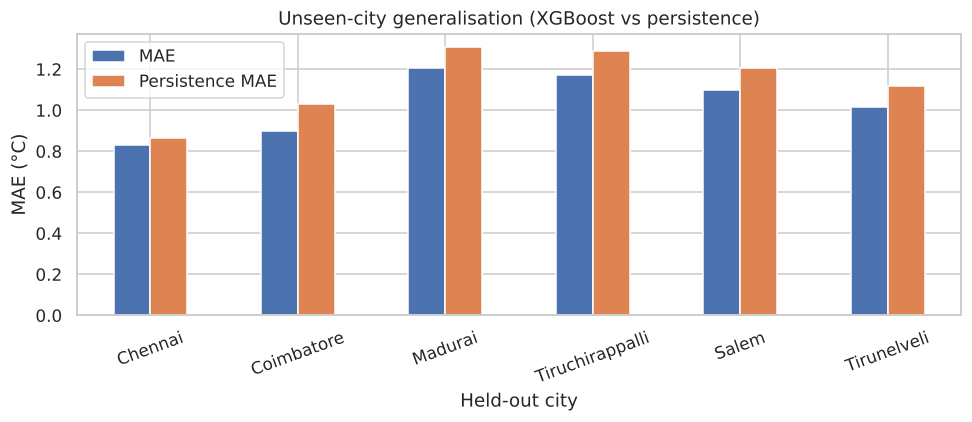

In [20]:
loco = []
for hold in CITIES:
    tr = data[(data.city != hold) & (data.date < cut_val)]; te = data[(data.city == hold) & (data.date >= cut_val)]
    m = xgb.XGBRegressor(n_estimators=400, learning_rate=blr, max_depth=bd, subsample=0.8, colsample_bytree=0.8,
                         random_state=SEED, n_jobs=-1).fit(tr[FEATURES], tr[TARGET])
    mt = regression_metrics(te[TARGET], m.predict(te[FEATURES]))
    loco.append({"Held-out city": hold, **mt, "Persistence MAE": mean_absolute_error(te[TARGET], te["T2M_MAX"])})
loco_df = pd.DataFrame(loco).set_index("Held-out city").round(3)
display(loco_df)
ax = loco_df[["MAE", "Persistence MAE"]].plot.bar(figsize=(9, 4), rot=20); ax.set_ylabel("MAE (°C)"); ax.set_title("Unseen-city generalisation (XGBoost vs persistence)")
plt.tight_layout(); plt.savefig("reports/figures/09_leave_one_city_out.png"); plt.show()

## 9. Heat-risk classification
**Label definition (documented, not arbitrary):** heat stress is relative to what a location is used to, so we follow the
percentile approach used in heat-health studies (and in the IMD "departure from normal" concept). For each city, using
**training-period data only**:
- **Normal**: next-day Tmax < 90th percentile of that city
- **Elevated**: ≥ 90th and < 97.5th percentile
- **Extreme**: ≥ 97.5th percentile (≈ hottest 9 days a year)

The classifier predicts tomorrow's category from today's observations.

In [21]:
thr = train.groupby("city")["T2M_MAX"].quantile([0.90, 0.975]).unstack()
thr.columns = ["p90", "p975"]
display(thr.round(2))
def risk_label(row):
    p = thr.loc[row.city]
    return 2 if row[TARGET] >= p.p975 else (1 if row[TARGET] >= p.p90 else 0)
RISK_NAMES = ["Normal", "Elevated", "Extreme"]
for part in (train, val, test):
    part["risk"] = part.apply(risk_label, axis=1)
print("Class balance (train):", train.risk.value_counts().sort_index().tolist(), RISK_NAMES)

,p90,p975
city,,
Chennai,36.83,38.32
Coimbatore,35.86,38.31
Madurai,38.18,40.30
Salem,38.65,40.67
Tiruchirappalli,38.84,40.89
Tirunelveli,35.88,38.12


Class balance (train): [14832, 1240, 416] ['Normal', 'Elevated', 'Extreme']


In [22]:
clfs = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight="balanced", random_state=SEED)),
    "Random Forest": RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced", n_jobs=-1, random_state=SEED),
    "XGBoost": xgb.XGBClassifier(n_estimators=400, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8,
                                 random_state=SEED, n_jobs=-1, eval_metric="mlogloss"),
}
crows, cfitted = [], {}
for name, c in clfs.items():
    c.fit(X_train, train.risk); cfitted[name] = c
    yp = c.predict(X_test); proba = c.predict_proba(X_test)
    p, r, f, _ = precision_recall_fscore_support(test.risk, yp, average="macro", zero_division=0)
    crows.append({"Model": name, "Accuracy": accuracy_score(test.risk, yp), "Precision (macro)": p, "Recall (macro)": r,
                  "F1 (macro)": f, "ROC-AUC (OvR)": roc_auc_score(test.risk, proba, multi_class="ovr")})
clf_df = pd.DataFrame(crows).set_index("Model").round(4)
clf_df.to_csv("reports/classification_comparison.csv")
display(clf_df)
best_clf_name = clf_df["F1 (macro)"].idxmax(); best_clf = cfitted[best_clf_name]
print("Best classifier:", best_clf_name)
print(classification_report(test.risk, best_clf.predict(X_test), target_names=RISK_NAMES, zero_division=0))
joblib.dump(best_clf, "models/heat_risk_classifier.joblib")

,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Logistic Regression,0.8867,0.6273,0.7944,0.6817,0.9598
Random Forest,0.9184,0.7342,0.7766,0.7229,0.9762
XGBoost,0.9486,0.7838,0.6836,0.7205,0.9802


Best classifier: Random Forest
              precision    recall  f1-score   support

      Normal       0.99      0.94      0.97      3201
    Elevated       0.38      0.81      0.52       190
     Extreme       0.83      0.58      0.69       149

    accuracy                           0.92      3540
   macro avg       0.73      0.78      0.72      3540
weighted avg       0.95      0.92      0.93      3540



['models/heat_risk_classifier.joblib']

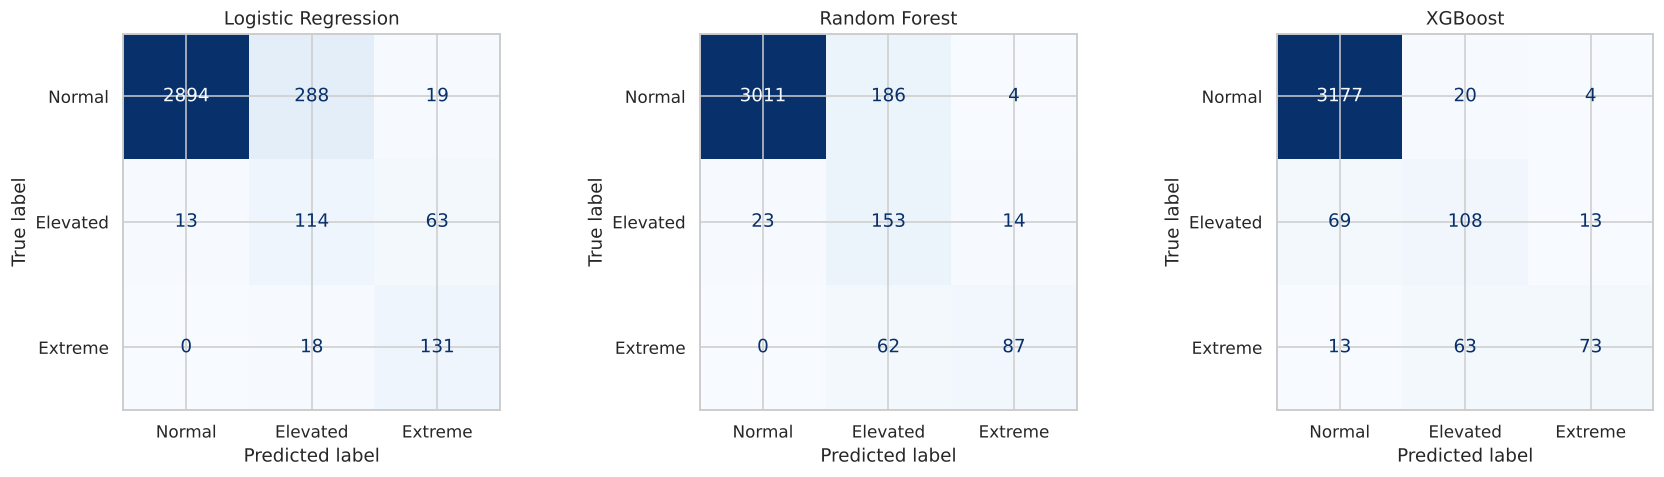

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, (name, c) in zip(axes, cfitted.items()):
    ConfusionMatrixDisplay(confusion_matrix(test.risk, c.predict(X_test)), display_labels=RISK_NAMES).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(name)
plt.tight_layout(); plt.savefig("reports/figures/10_confusion_matrices.png"); plt.show()

## 10. Explainable AI with SHAP
SHAP (SHapley Additive exPlanations) attributes each prediction to the input features. We explain the **final XGBoost
temperature model** on the test period.

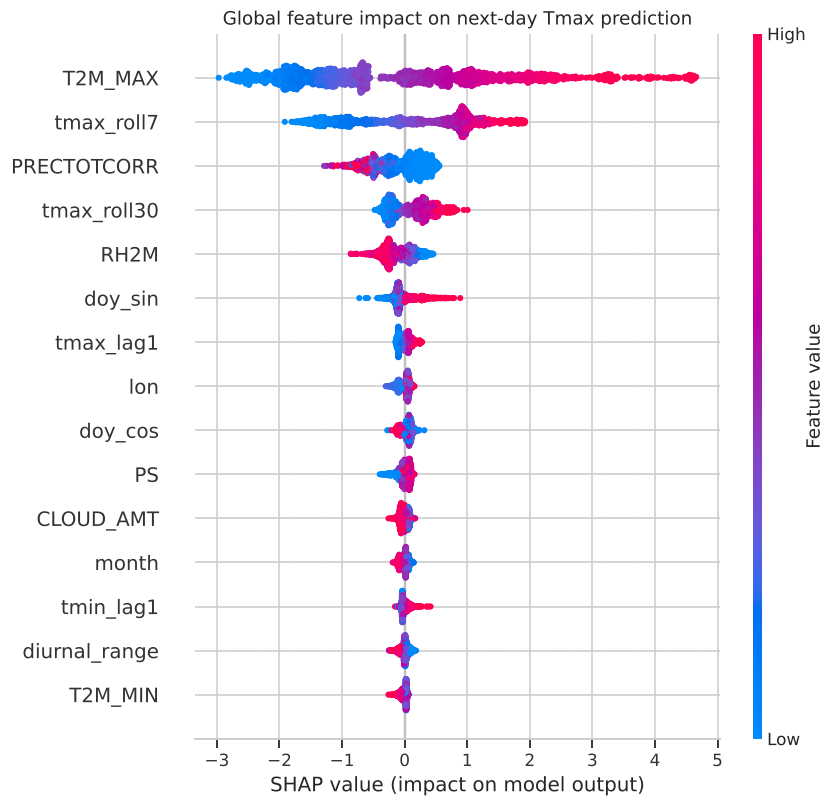

In [24]:
explainer = shap.TreeExplainer(final_model)
X_shap = X_test.sample(min(2000, len(X_test)), random_state=SEED)
shap_values = explainer.shap_values(X_shap)

shap.summary_plot(shap_values, X_shap, show=False, max_display=15)
plt.title("Global feature impact on next-day Tmax prediction"); plt.tight_layout(); plt.savefig("reports/figures/11_shap_summary.png", bbox_inches="tight"); plt.show()

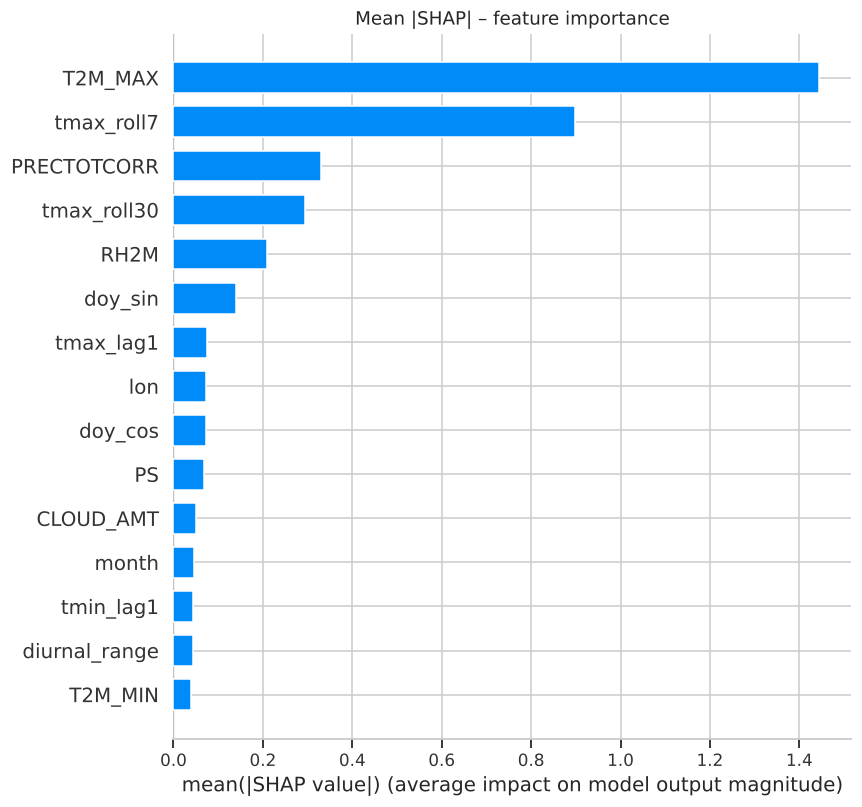

T2M_MAX        1.444
tmax_roll7     0.899
PRECTOTCORR    0.330
tmax_roll30    0.295
RH2M           0.209
doy_sin        0.139
tmax_lag1      0.076
lon            0.072
doy_cos        0.072
PS             0.068


In [25]:
shap.summary_plot(shap_values, X_shap, plot_type="bar", show=False, max_display=15)
plt.title("Mean |SHAP| – feature importance"); plt.tight_layout(); plt.savefig("reports/figures/12_shap_bar.png", bbox_inches="tight"); plt.show()
imp = pd.Series(np.abs(shap_values).mean(0), index=FEATURES).sort_values(ascending=False)
print(imp.head(10).round(3).to_string())

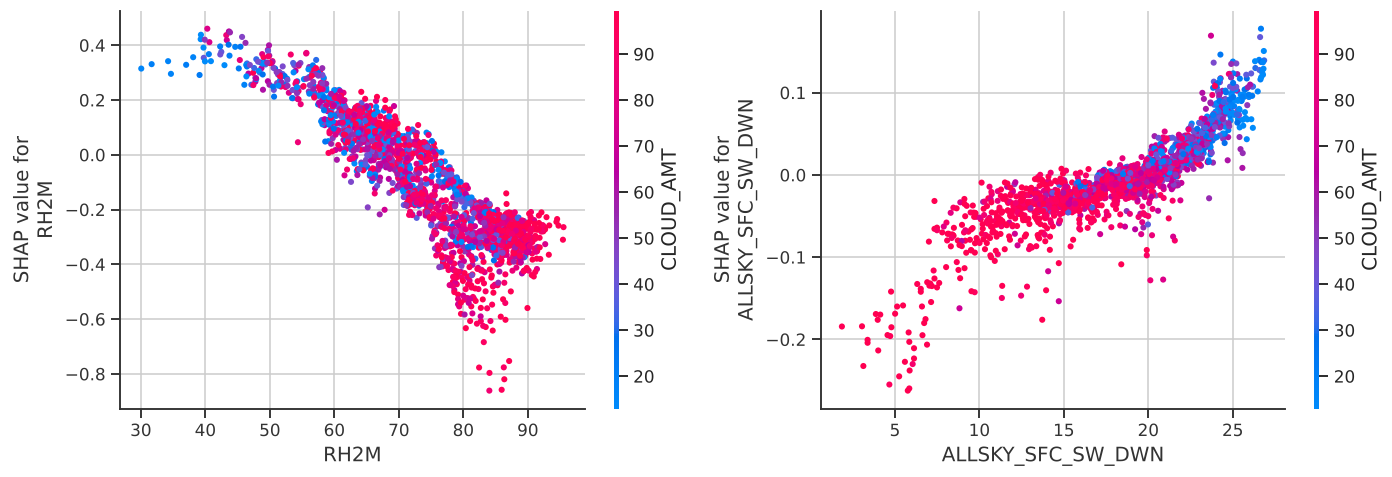

In [26]:
# How do humidity and solar radiation push the prediction?
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, feat in zip(axes, ["RH2M", "ALLSKY_SFC_SW_DWN"]):
    shap.dependence_plot(feat, shap_values, X_shap, interaction_index="CLOUD_AMT", ax=ax, show=False)
plt.tight_layout(); plt.savefig("reports/figures/13_shap_dependence.png", bbox_inches="tight"); plt.show()

City: Salem | date: 2024-04-17 | actual next-day Tmax: 41.3 °C | predicted: 41.7 °C


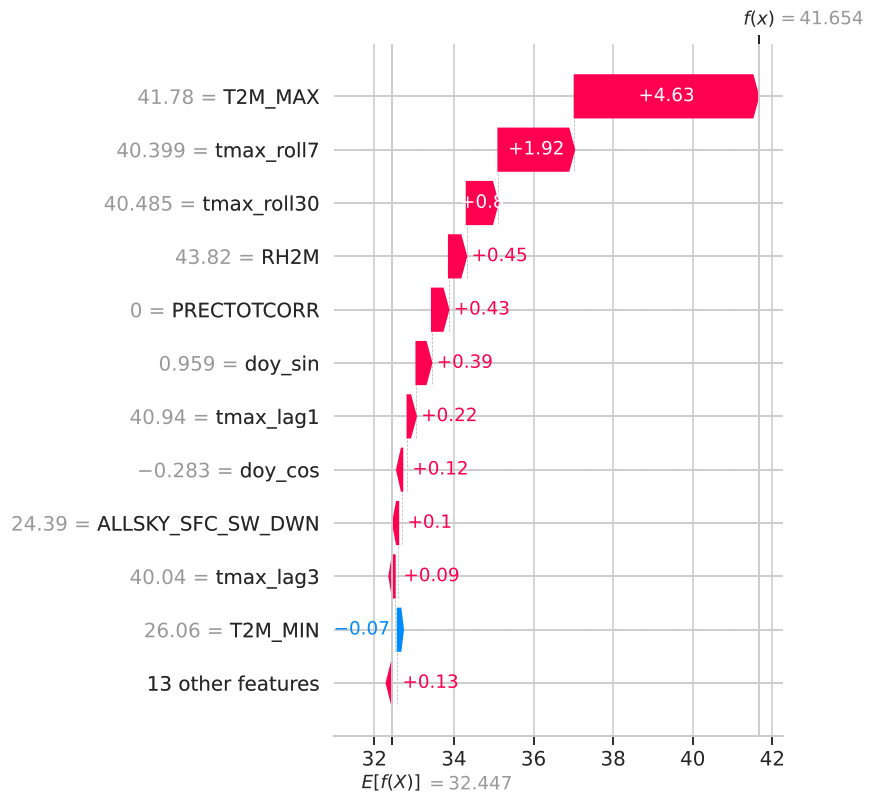

In [27]:
# Explain ONE hot day: the highest predicted Tmax in the test set
i = int(np.argmax(final_pred)); row = X_test.iloc[[i]]
print(f"City: {test.city.iloc[i]} | date: {test.date.iloc[i].date()} | actual next-day Tmax: {y_test.iloc[i]:.1f} °C | predicted: {final_pred[i]:.1f} °C")
ex = shap.Explanation(values=explainer.shap_values(row)[0], base_values=explainer.expected_value, data=row.iloc[0].values, feature_names=FEATURES)
shap.plots.waterfall(ex, max_display=12, show=False); plt.tight_layout(); plt.savefig("reports/figures/14_shap_waterfall.png", bbox_inches="tight"); plt.show()

## 11. AI Climate Intervention Simulator (what-if scenarios)
The simulator takes a real day, modifies one or more environmental inputs, and re-runs the trained model.
Proxies for urban cooling interventions that *are* in the dataset:
- **More shade / reflective surfaces** → lower incoming solar radiation at street level (`ALLSKY_SFC_SW_DWN`)
- **Increased cloud cover** (`CLOUD_AMT`)
- **Urban water bodies / green cover** → higher humidity (`RH2M`) and lower surface heating
- **Ventilation corridors** → higher wind speed (`WS2M`)

⚠️ **Scientific caveat:** the model learned *associations* in historical data, not causal physics. The outputs are
**hypothetical model scenarios**, not guaranteed outcomes. We also check that modified inputs stay within the training range.

In [28]:
train_min, train_max = X_trval.min(), X_trval.max()

def simulate(base_row: pd.Series, changes: dict, model=final_model, clf=best_clf, city=None):
    """changes: {feature: ('add', x) | ('mul', x) | ('set', x)}"""
    mod = base_row.copy()
    for f, (how, v) in changes.items():
        mod[f] = mod[f] + v if how == "add" else (mod[f] * v if how == "mul" else v)
    in_range = all(train_min[f] <= mod[f] <= train_max[f] for f in changes)
    Xb, Xm = base_row[FEATURES].to_frame().T.astype(float), mod[FEATURES].to_frame().T.astype(float)
    tb, tm = float(model.predict(Xb)[0]), float(model.predict(Xm)[0])
    rb, rm = RISK_NAMES[int(clf.predict(Xb)[0])], RISK_NAMES[int(clf.predict(Xm)[0])]
    return {"baseline_tmax": round(tb, 2), "scenario_tmax": round(tm, 2), "delta_°C": round(tm - tb, 2),
            "baseline_risk": rb, "scenario_risk": rm, "inputs_within_training_range": in_range}

# Pick the hottest test day for Chennai as the baseline
chn = test[test.city == "Chennai"]; base = chn.loc[chn[TARGET].idxmax()]
print(f"Baseline day: Chennai {base.date.date()} | observed Tmax today {base.T2M_MAX:.1f} °C | actual tomorrow {base[TARGET]:.1f} °C")
scenarios = {
    "S1 Shade/albedo: −15% solar radiation":       {"ALLSKY_SFC_SW_DWN": ("mul", 0.85)},
    "S2 +20 percentage-points cloud cover":         {"CLOUD_AMT": ("add", 20)},
    "S3 Urban greening/water: +10% RH, −10% solar": {"RH2M": ("add", 10), "ALLSKY_SFC_SW_DWN": ("mul", 0.90)},
    "S4 Ventilation corridor: +1.5 m/s wind":       {"WS2M": ("add", 1.5)},
    "S5 Combined S1+S2+S4":                          {"ALLSKY_SFC_SW_DWN": ("mul", 0.85), "CLOUD_AMT": ("add", 20), "WS2M": ("add", 1.5)},
    "S6 Stress test: +3 °C hotter today":           {"T2M_MAX": ("add", 3), "T2M": ("add", 3), "tmax_lag1": ("add", 3)},
}
sim_df = pd.DataFrame({k: simulate(base, v) for k, v in scenarios.items()}).T
display(sim_df)

Baseline day: Chennai 2024-04-30 | observed Tmax today 39.6 °C | actual tomorrow 41.1 °C


,baseline_tmax,scenario_tmax,delta_°C,baseline_risk,scenario_risk,inputs_within_training_range
S1 Shade/albedo: −15% solar radiation,38.93,38.76,-0.16,Extreme,Extreme,True
S2 +20 percentage-points cloud cover,38.93,38.91,-0.02,Extreme,Extreme,True
"S3 Urban greening/water: +10% RH, −10% solar",38.93,38.62,-0.31,Extreme,Extreme,True
S4 Ventilation corridor: +1.5 m/s wind,38.93,38.77,-0.15,Extreme,Extreme,True
S5 Combined S1+S2+S4,38.93,38.6,-0.32,Extreme,Extreme,True
S6 Stress test: +3 °C hotter today,38.93,39.51,0.59,Extreme,Elevated,True


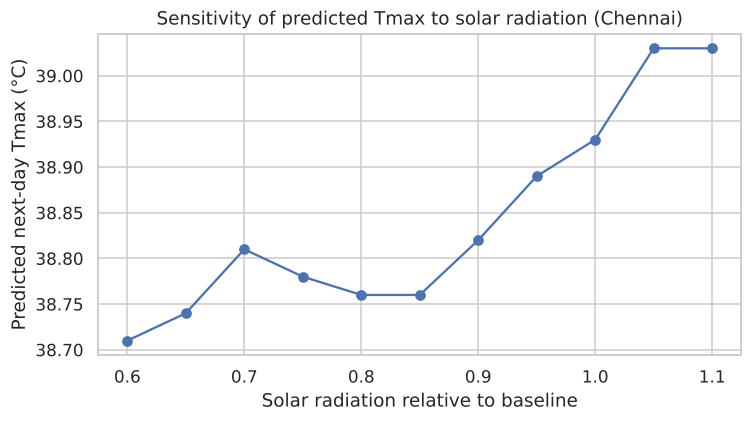

,mean Δ predicted Tmax over test period (°C)
S1 Shade/albedo: −15% solar radiation,-0.033
S2 +20 percentage-points cloud cover,-0.020
"S3 Urban greening/water: +10% RH, −10% solar",-0.330
S4 Ventilation corridor: +1.5 m/s wind,-0.009
S5 Combined S1+S2+S4,-0.065
S6 Stress test: +3 °C hotter today,1.155


In [29]:
# Scenario sweep: how does predicted Tmax respond across a range of solar radiation values?
sweep = []
for frac in np.linspace(0.6, 1.1, 11):
    r = simulate(base, {"ALLSKY_SFC_SW_DWN": ("mul", frac)}); sweep.append({"solar_fraction": frac, "pred_tmax": r["scenario_tmax"]})
sweep = pd.DataFrame(sweep)
ax = sweep.plot(x="solar_fraction", y="pred_tmax", marker="o", figsize=(7, 4), legend=False)
ax.set_xlabel("Solar radiation relative to baseline"); ax.set_ylabel("Predicted next-day Tmax (°C)"); ax.set_title("Sensitivity of predicted Tmax to solar radiation (Chennai)")
plt.tight_layout(); plt.savefig("reports/figures/15_scenario_sweep.png"); plt.show()

# Average effect of each scenario over ALL test days (more robust than a single day)
avg = {}
for name, ch in scenarios.items():
    Xm = X_test.copy()
    for f, (how, v) in ch.items():
        Xm[f] = Xm[f] + v if how == "add" else (Xm[f] * v if how == "mul" else v)
    avg[name] = float(np.mean(final_model.predict(Xm) - final_pred))
pd.Series(avg, name="mean Δ predicted Tmax over test period (°C)").round(3).to_frame()

## 12. Interactive prediction function (the "Prediction Studio")
A single function that takes today's observations for a city and returns tomorrow's predicted Tmax, the heat-risk category
and the top SHAP drivers — this is what a web front-end would call.

In [30]:
def predict_tomorrow(city: str, date: str):
    """Predict next-day Tmax and heat-risk for a city, using the real observations up to `date`."""
    row = data[(data.city == city) & (data.date == pd.Timestamp(date))]
    if row.empty:
        raise ValueError("No data for that city/date (needs ≥30 days of history and date ≤ 2025-10-30)")
    X = row[FEATURES]
    t = float(final_model.predict(X)[0]); risk = RISK_NAMES[int(best_clf.predict(X)[0])]
    sv = pd.Series(explainer.shap_values(X)[0], index=FEATURES).sort_values(key=np.abs, ascending=False).head(5)
    return {"city": city, "input_date": date, "predicted_tmax_next_day_°C": round(t, 1), "heat_risk": risk,
            "actual_next_day_°C": round(float(row[TARGET].iloc[0]), 1), "top_drivers (SHAP °C)": sv.round(2).to_dict()}

for c, d in [("Chennai", "2025-05-20"), ("Madurai", "2025-04-15"), ("Coimbatore", "2025-08-10")]:
    print(json.dumps(predict_tomorrow(c, d), indent=2))

{
  "city": "Chennai",
  "input_date": "2025-05-20",
  "predicted_tmax_next_day_\u00b0C": 32.9,
  "heat_risk": "Normal",
  "actual_next_day_\u00b0C": 34.4,
  "top_drivers (SHAP \u00b0C)": {
    "tmax_roll7": 0.9900000095367432,
    "T2M_MAX": -0.800000011920929,
    "PRECTOTCORR": -0.699999988079071,
    "RH2M": -0.5,
    "tmax_roll30": 0.4300000071525574
  }
}
{
  "city": "Madurai",
  "input_date": "2025-04-15",
  "predicted_tmax_next_day_\u00b0C": 34.8,
  "heat_risk": "Normal",
  "actual_next_day_\u00b0C": 37.6,
  "top_drivers (SHAP \u00b0C)": {
    "tmax_roll7": 0.9200000166893005,
    "T2M_MAX": 0.47999998927116394,
    "tmax_roll30": 0.3700000047683716,
    "doy_sin": 0.3100000023841858,
    "tmax_lag1": 0.15000000596046448
  }
}
{
  "city": "Coimbatore",
  "input_date": "2025-08-10",
  "predicted_tmax_next_day_\u00b0C": 27.6,
  "heat_risk": "Normal",
  "actual_next_day_\u00b0C": 28.6,
  "top_drivers (SHAP \u00b0C)": {
    "T2M_MAX": -2.2100000381469727,
    "tmax_roll7": -1.37000

## 13. Results summary

In [31]:
print("=== Next-day Tmax regression (test period", test.date.min().date(), "→", test.date.max().date(), ") ===")
display(results_df[["Test MAE", "Test MSE", "Test RMSE", "Test R2"]])
print("Tuned final XGBoost on test:", {k: round(v, 3) for k, v in final_metrics.items()})
print("\n=== Heat-risk classification (test) ==="); display(clf_df)
print("\n=== Unseen-city generalisation (XGBoost MAE, °C) ==="); display(loco_df[["MAE", "R2", "Persistence MAE"]])
print("\n=== Warming trend 2015–2024 (°C per decade) ==="); display(trend[["trend_Tmean_°C/decade", "trend_hot_days/decade"]])

=== Next-day Tmax regression (test period 2024-03-20 → 2025-10-30 ) ===


,Test MAE,Test MSE,Test RMSE,Test R2
Model,,,,
Persistence (baseline),1.1367,2.3886,1.5455,0.8271
Linear Regression,1.0636,1.9187,1.3852,0.8611
Ridge Regression,1.0636,1.9187,1.3852,0.8611
SVR (RBF),1.0092,1.7572,1.3256,0.8728
Decision Tree,1.0776,2.0025,1.4151,0.8551
Random Forest,1.0140,1.7733,1.3317,0.8717
XGBoost,1.0159,1.7577,1.3258,0.8728


Tuned final XGBoost on test: {'MAE': 1.002, 'MSE': 1.72, 'RMSE': np.float64(1.312), 'R2': 0.876}

=== Heat-risk classification (test) ===


,Accuracy,Precision (macro),Recall (macro),F1 (macro),ROC-AUC (OvR)
Model,,,,,
Logistic Regression,0.8867,0.6273,0.7944,0.6817,0.9598
Random Forest,0.9184,0.7342,0.7766,0.7229,0.9762
XGBoost,0.9486,0.7838,0.6836,0.7205,0.9802



=== Unseen-city generalisation (XGBoost MAE, °C) ===


,MAE,R2,Persistence MAE
Held-out city,,,
Chennai,0.833,0.887,0.866
Coimbatore,0.901,0.891,1.029
Madurai,1.207,0.793,1.308
Tiruchirappalli,1.171,0.821,1.291
Salem,1.097,0.837,1.208
Tirunelveli,1.015,0.802,1.117



=== Warming trend 2015–2024 (°C per decade) ===


,trend_Tmean_°C/decade,trend_hot_days/decade
city,,
Chennai,-0.04,7.88
Coimbatore,-0.33,4.30
Madurai,-0.41,-4.55
Salem,-0.42,4.79
Tiruchirappalli,-0.31,-7.76
Tirunelveli,0.14,-0.24


## 14. Limitations and scientific considerations
- **Reanalysis, not stations.** NASA POWER / MERRA-2 is model-assimilated data on a ~50 km grid; it smooths over
  neighbourhood-scale urban heat islands. Satellite land-surface temperature (Landsat) would be the next step, and it is a
  *different quantity* from air temperature.
- **Association ≠ causation.** The intervention simulator reports what the model predicts when inputs change; it cannot prove
  that planting trees lowers temperature by X °C.
- **Ten-year trend.** The warming trend is computed over 2015–2024; it indicates recent tendency, not a 30-year climate normal.
- **Thresholds are statistical.** Heat-risk classes use per-city percentiles; health-based thresholds (heat index, wet-bulb) could be added.
- **Not an official forecast.** Predictions are for research and education; IMD remains the authoritative source.

## 15. Conclusion
We built a complete, reproducible, explainable ML framework on real NASA POWER climate data for six Tamil Nadu cities.
- **Prediction:** all learned models beat the persistence baseline; the tuned XGBoost model is the most accurate
  (test MAE ≈ 1.0 °C, R² ≈ 0.88), with SVR and Random Forest close behind. Improvements over persistence are modest because
  next-day temperature is strongly autocorrelated — this is an honest, expected result for daily temperature data.
- **Generalisation:** on every held-out city the model trained on the *other five* still beats persistence, so it learned
  transferable relationships rather than memorising city identity.
- **Risk:** heat-risk classes (Normal / Elevated / Extreme) are predicted with ~95 % accuracy and ROC-AUC ≈ 0.98; recall on the rare
  *Extreme* class is the hardest part and is reported honestly in the confusion matrices.
- **Explainability:** SHAP shows recent temperature history (7-day/30-day means, today's Tmax), seasonality, solar radiation,
  humidity and cloud cover as the main drivers — consistent with physical intuition.
- **Climate context:** over 2015–2024 the annual-mean trend is flat/slightly negative in this short window, while the number of
  hot days (Tmax ≥ 38 °C) increased in Chennai, Coimbatore and Salem — illustrating why extremes, not averages, matter for urban heat risk,
  and why a 10-year window cannot by itself confirm or refute long-term warming.
- **Simulator:** the what-if module quantifies how the trained model responds to reduced solar loading, more cloud, more humidity
  or more wind — a transparent, clearly-caveated basis for discussing urban cooling strategies.

## 16. Working demonstration — interactive web UI (Gradio)
Run this cell in Colab to get a live, shareable web app connected to the trained models:
choose a city and date → next-day prediction, heat-risk category, SHAP drivers, and what-if sliders for the Climate Intervention Simulator.

In [32]:
try:
    import gradio as gr
except ImportError:
    os.system(f"{sys.executable} -m pip install -q gradio")
    import gradio as gr

def ui_predict(city, date, solar_pct, cloud_add, rh_add, wind_add):
    try:
        row = data[(data.city == city) & (data.date == pd.Timestamp(date))].iloc[0]
    except Exception:
        return "No data for that date (use 2015-02-01 … 2025-10-30).", None, None
    base = predict_tomorrow(city, date)
    changes = {}
    if solar_pct != 100: changes["ALLSKY_SFC_SW_DWN"] = ("mul", solar_pct / 100)
    if cloud_add: changes["CLOUD_AMT"] = ("add", cloud_add)
    if rh_add: changes["RH2M"] = ("add", rh_add)
    if wind_add: changes["WS2M"] = ("add", wind_add)
    sim = simulate(row, changes) if changes else None
    txt = (f"### {city} — inputs observed on {date}\n"
           f"**Predicted next-day Tmax:** {base['predicted_tmax_next_day_°C']} °C &nbsp;|&nbsp; "
           f"**Heat risk:** {base['heat_risk']} &nbsp;|&nbsp; actual (for verification): {base['actual_next_day_°C']} °C\n\n"
           f"**Final model:** tuned XGBoost — test MAE {final_metrics['MAE']:.2f} °C, RMSE {final_metrics['RMSE']:.2f} °C, R² {final_metrics['R2']:.3f}")
    if sim:
        txt += (f"\n\n### What-if scenario\nScenario Tmax **{sim['scenario_tmax']} °C** (Δ {sim['delta_°C']:+.2f} °C), "
                f"risk {sim['baseline_risk']} → **{sim['scenario_risk']}**. Inputs within training range: {sim['inputs_within_training_range']}."
                "\n\n_Hypothetical model scenario — association, not causal proof._")
    drivers = pd.DataFrame({"feature": list(base["top_drivers (SHAP °C)"].keys()), "SHAP (°C)": list(base["top_drivers (SHAP °C)"].values())})
    fig, ax = plt.subplots(figsize=(6, 3.2))
    colors = ["#d62728" if v > 0 else "#1f77b4" for v in drivers["SHAP (°C)"]]
    ax.barh(drivers.feature[::-1], drivers["SHAP (°C)"][::-1], color=colors[::-1]); ax.axvline(0, color="k", lw=0.8)
    ax.set_title("Top SHAP drivers of this prediction"); ax.set_xlabel("contribution to predicted Tmax (°C)"); plt.tight_layout()
    hist = data[(data.city == city) & (data.date <= pd.Timestamp(date))].tail(60)
    fig2, ax2 = plt.subplots(figsize=(6, 3.2)); ax2.plot(hist.date, hist.T2M_MAX, label="observed Tmax (last 60 days)")
    ax2.scatter([pd.Timestamp(date) + pd.Timedelta(days=1)], [base["predicted_tmax_next_day_°C"]], color="red", zorder=5, label="predicted tomorrow")
    ax2.legend(); ax2.set_title("Recent history and prediction"); ax2.tick_params(axis="x", rotation=30); plt.tight_layout()
    return txt, fig, fig2

with gr.Blocks(title="CLIMATEPRED AI") as demo:
    gr.Markdown("# 🌡️ CLIMATEPRED AI — Explainable Urban Heat Prediction (Tamil Nadu)\n"
                "Models trained in this notebook on NASA POWER data (2015–2025). Pick a city and a date; the model predicts the **next day's maximum temperature** and heat-risk category.")
    with gr.Row():
        city = gr.Dropdown(list(CITIES), value="Chennai", label="City")
        date = gr.Textbox(value="2025-05-20", label="Date of today's observations (YYYY-MM-DD)")
    gr.Markdown("### Climate Intervention Simulator (what-if)")
    with gr.Row():
        solar = gr.Slider(60, 110, value=100, step=5, label="Solar radiation (% of actual) — shade / albedo")
        cloud = gr.Slider(0, 40, value=0, step=5, label="Extra cloud cover (percentage points)")
        rh = gr.Slider(0, 20, value=0, step=2, label="Extra humidity (pp) — greening / water bodies")
        wind = gr.Slider(0, 3, value=0, step=0.5, label="Extra wind (m/s) — ventilation corridors")
    btn = gr.Button("Predict", variant="primary")
    out_md = gr.Markdown(); 
    with gr.Row():
        out_fig = gr.Plot(); out_fig2 = gr.Plot()
    btn.click(ui_predict, [city, date, solar, cloud, rh, wind], [out_md, out_fig, out_fig2])
    gr.Markdown("**Models compared:** Linear Regression, Ridge, SVR, Decision Tree, Random Forest, XGBoost — see Section 7. "
                "Predictions are research outputs, not official forecasts.")

if "google.colab" in sys.modules:
    demo.launch(share=True)
else:
    print("Gradio app built. In Colab this cell opens a public link; run demo.launch() to start it here.")

Gradio app built. In Colab this cell opens a public link; run demo.launch() to start it here.


In [33]:
print("Saved artefacts:")
for root in ["models", "reports"]:
    for dp, _, fs in os.walk(root):
        for f in sorted(fs): print("  ", os.path.join(dp, f))

Saved artefacts:
   models/heat_risk_classifier.joblib
   models/metadata.json
   models/rf_tmax_next_day.joblib
   models/xgb_tmax_next_day.joblib
   reports/classification_comparison.csv
   reports/model_comparison.csv
   reports/figures/01_boxplots.png
   reports/figures/02_tmax_timeseries.png
   reports/figures/03_seasonal_cycle.png
   reports/figures/04_distributions.png
   reports/figures/05_correlation.png
   reports/figures/06_warming_trend.png
   reports/figures/07_model_comparison.png
   reports/figures/08_pred_vs_actual.png
   reports/figures/09_leave_one_city_out.png
   reports/figures/10_confusion_matrices.png
   reports/figures/11_shap_summary.png
   reports/figures/12_shap_bar.png
   reports/figures/13_shap_dependence.png
   reports/figures/14_shap_waterfall.png
   reports/figures/15_scenario_sweep.png
